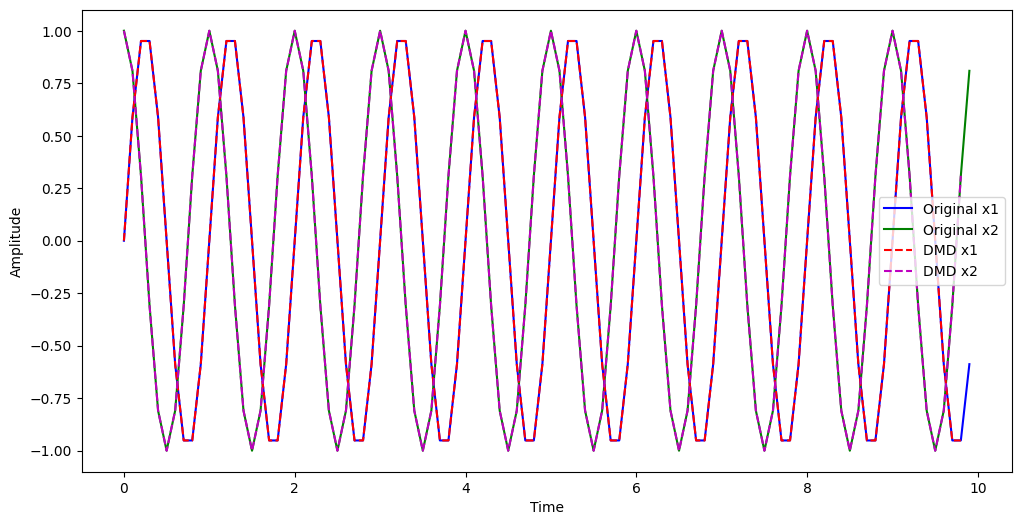

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd

def dmd(X, Y, r):
    U, S, Vh = svd(X, full_matrices=False)
    U_r = U[:, :r]
    S_r = S[:r]
    V_r = Vh.conj().T[:, :r]

    A_tilde = U_r.T @ Y @ V_r @ np.diag(1.0 / S_r)
    Lambda, W = np.linalg.eig(A_tilde)

    Phi = Y @ V_r @ np.diag(1.0 / S_r) @ W
    omega = np.log(Lambda) / dt
    b = np.linalg.lstsq(Phi, X[:, 0], rcond=None)[0]

    return Phi, omega, b

# Create synthetic data
dt = 0.1
t = np.arange(0, 10, dt)
x1 = np.sin(2 * np.pi * t)
x2 = np.cos(2 * np.pi * t)
X = np.vstack([x1, x2]).T

# Create snapshot matrices X and Y
X1 = X[:-1, :].T
X2 = X[1:, :].T

# Perform DMD with rank truncation r=2
r = 2
Phi, omega, b = dmd(X1, X2, r)

# Reconstruct the system dynamics
time_dynamics = np.zeros((r, len(t) - 1), dtype=complex)
for i in range(r):
    time_dynamics[i, :] = b[i] * np.exp(omega[i] * t[:-1])

X_dmd = np.dot(Phi, time_dynamics).real

# Plot the original and reconstructed data
plt.figure(figsize=(12, 6))
plt.plot(t, X[:, 0], 'b', label='Original x1')
plt.plot(t, X[:, 1], 'g', label='Original x2')
plt.plot(t[:-1], X_dmd[0, :], 'r--', label='DMD x1')
plt.plot(t[:-1], X_dmd[1, :], 'm--', label='DMD x2')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.show()






x1 اصلی (آبی) و x2 (سبز): اینها امواج سینوسی و کسینوس مصنوعی هستند که  ایجاد کردیم.

DMD x1 (قرمز خط چین) و DMD x2 (خارجی چین): اینها نسخه های بازسازی شده با DMD سیگنال های اصلی هستند.

با مقایسه سیگنال های اصلی و بازسازی شده، می توانید متوجه شوید که DMD چقدر دینامیک سیستم را به تصویر می کشد.

خلاصه داستان
اگر سیگنال‌های بازسازی‌شده (DMD x1 و DMD x2) دقیقاً از سیگنال‌های اصلی (Original x1 و Original x2) پیروی کنند، به این معنی است که DMD به‌دقت دینامیک سیستم را ثبت کرده است.

انحرافات جزئی بین سیگنال های اصلی و بازسازی شده ممکن است به دلیل تقریب عددی یا برش وجود داشته باشد.